# Fiche 8 — Du chronomètre au budget

| | |
|---|---|
| 🎯 **Objectif** | Résumer des temps de réponse mesurés, en déduire un débit et un coût pour 500 000 images, selon deux façons de payer |
| ⏱️ **Durée** | 45 min |
| 🧰 **Prérequis** | Fiche 4 |
| 🔗 **Dans le projet** | Seconde tâche du brief : chiffrer 500 000 images sur 30 jours |

> **L'idée clé.** Un budget se construit en trois briques : **combien** (le volume), **combien de temps** par image (mesuré, pas deviné), **combien coûte** une seconde ou une heure de machine. Le reste est une multiplication.

## 1. Résumer des temps de réponse

Le journal des 50 appels (JPEG 512 px) donne la durée de chaque requête.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from segvet import cache, cost, viz

viz.apply_style()
journal = cache.read_log("jpeg512")
duree = journal["seconds"]
print(f"moyenne {duree.mean():.2f} s | médiane {duree.median():.2f} s | 95e centile {duree.quantile(0.95):.2f} s | max {round(duree.max(), 2)} s")

moyenne 0.90 s | médiane 0.71 s | 95e centile 1.24 s | max 4.36 s


On résume par la **médiane** (la moitié des appels sont plus rapides) et le **95ᵉ centile** (95 % des appels sont
plus rapides) : la moyenne est tirée vers le haut par quelques appels lents, typiquement le premier, quand le
service se réveille.

## ⚠️ Piège : chronométrer plus que ce qu'on croit

Un premier passage de ce projet a mesuré le temps **depuis le début de la fonction**, y compris la pause imposée par
notre propre limiteur (30 requêtes par minute). Résultat : des « latences » de 36 s qui n'avaient rien à voir avec
l'API. Le journal fautif est conservé ; comparons-le au bon.

In [2]:
fautif = pd.read_json(cache.PROCESSED_DIR / "journal_v1_attente_incluse_jpeg512.jsonl", lines=True)
comparaison = pd.DataFrame({
    "journal fautif (attente comprise)": fautif["seconds"].describe(percentiles=[0.5, 0.95]),
    "journal corrigé (requête seule)": duree.describe(percentiles=[0.5, 0.95]),
}).loc[["mean", "50%", "95%", "max"]].rename(index={"mean": "moyenne", "50%": "médiane", "95%": "95e centile"})
comparaison.round(2)

,journal fautif (attente comprise),journal corrigé (requête seule)
moyenne,1.60,0.90
médiane,0.68,0.71
95e centile,4.15,1.24
max,36.14,4.36


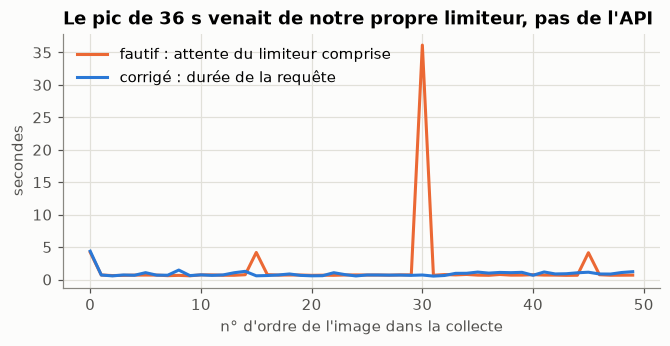

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(fautif.sort_values("order")["seconds"].to_numpy(), color=viz.ORANGE, lw=2, label="fautif : attente du limiteur comprise")
ax.plot(journal.sort_values("order")["seconds"].to_numpy(), color=viz.BLUE, lw=2, label="corrigé : durée de la requête")
ax.set_xlabel("n° d'ordre de l'image dans la collecte")
ax.set_ylabel("secondes")
ax.set_title("Le pic de 36 s venait de notre propre limiteur, pas de l'API")
ax.legend()
plt.show()

**Lecture.** La médiane bouge peu, mais la moyenne et le maximum explosent : un budget calculé avec la moyenne
fautive aurait été faux. Le remède : chronométrer **juste autour** de ce qu'on veut mesurer (ici, l'appel
`requests.post`), et noter à part le temps total. Un test automatique vérifie désormais que la pause du limiteur
n'est plus comptée.

## 2. Le débit nécessaire

500 000 images en 30 jours, cela fait en moyenne :

In [4]:
besoin = cost.required_rate_per_minute(500_000, 30)
print(f"{besoin:.1f} images par minute, soit une image toutes les {60 / besoin:.1f} s")
print(f"Un seul appel à la fois, à {duree.median():.2f} s par image, traite {60 / duree.median():.0f} images par minute")

11.6 images par minute, soit une image toutes les 5.2 s
Un seul appel à la fois, à 0.71 s par image, traite 84 images par minute


## 3. Deux façons de payer

| Façon de payer | On paie… | Formule |
|---|---|---|
| **À l'usage** (serverless, hf-inference) | le temps de calcul de chaque requête | images × secondes par image × prix par seconde |
| **Machine réservée** (endpoint dédié) | chaque heure où la machine est allumée, qu'elle travaille ou non | heures allumées × prix horaire |

Hugging Face ne publie pas de prix par seconde pour hf-inference. Méthode : après quelques centaines d'appels, lis
**ta propre facture** (page « Inference Providers » de ton compte) et divise par le nombre de requêtes. Pour une
machine réservée, on prend la grille publique des Inference Endpoints. Les prix ci-dessous sont des **exemples**,
pas ceux du projet : remplace-les par ce que tu trouves, avec la date.

In [5]:
n_images = 100_000                   # exemple : un autre volume que celui du projet
prix_par_image = 0.0001              # exemple : facture ÷ nombre de requêtes (prix par image, pas de temps ici)
prix_horaire = 0.10                  # exemple : une petite machine CPU
print(f"À l'usage : {n_images * prix_par_image:.0f} $ pour {n_images:,} images".replace(",", " "))
print(f"Machine allumée 30 jours : {cost.dedicated_cost(24 * 30, prix_horaire):.0f} $")

À l'usage : 10 $ pour 100 000 images
Machine allumée 30 jours : 72 $


## ⚠️ Piège : confondre des heures de machine et des requêtes

« Une machine dédiée, c'est 0,10 $ de l'heure, donc 100 000 images × 0,10 $ = 10 000 $ » : faux, on a multiplié des
**images** par un prix **horaire**. Le bon raisonnement passe par le temps : combien d'heures faut-il pour traiter
100 000 images ? La fonction `cost.batch_hours` fait ce calcul.

In [6]:
secondes_par_image = 2.0  # exemple : temps de calcul mesuré par image sur la machine
heures = cost.batch_hours(n_images, secondes_par_image)
print(f"Faux : {n_images * prix_horaire:,.0f} $".replace(",", " "), f"  |   Juste : {heures:.0f} h × {prix_horaire:.2f} $ = {cost.dedicated_cost(heures, prix_horaire):.2f} $".replace(".", ","))

Faux : 10 000 $   |   Juste : 56 h × 0,10 $ = 5,56 $


### ✍️ À toi de jouer

L'agence envisage 2 millions d'images par mois. Avec les prix d'exemple ci-dessus et 2 s par image, recalcule les trois coûts (à l'usage, machine allumée en permanence, machine par lots) et vérifie qu'**une** machine suffit pour le débit. Lequel des trois scénarios change d'avis ?

In [7]:
# Ta réponse ici

<details>
<summary><b>💡 Voir une solution</b> (après avoir cherché !)</summary>

```python
n = 2_000_000
print(f"à l'usage : {n * prix_par_image:.0f} $")
print(f"machine 24 h/24 : {cost.dedicated_cost(720, prix_horaire):.0f} $ (prix inchangé)")
h = cost.batch_hours(n, 2.0)
print(f"machine par lots : {h:.0f} h → {cost.dedicated_cost(h, prix_horaire):.0f} $")
print("heures nécessaires > 720 h du mois ?", h > 720)
print(f"débit requis {cost.required_rate_per_minute(n, 30):.0f}/min, une machine en fait {60 / 2.0:.0f}/min")
```

**Pourquoi ?** le coût à l'usage et le coût par lots grandissent avec le volume ; la machine allumée en permanence coûte le même prix tant qu'elle suffit. Avec 2 millions d'images, le besoin (46 images par minute) dépasse ce qu'une machine traite (30 par minute), et 1 111 h de calcul ne tiennent pas dans les 720 h d'un mois : il faut deux machines. Un chiffrage dit toujours **jusqu'à quel volume** il reste valable.

</details>

## ✅ À retenir

1. Résumer des durées par la **médiane** et le **95ᵉ centile**, pas par la moyenne.
2. Chronométrer seulement ce qu'on veut mesurer : ici, la pause du limiteur faussait la moyenne.
3. Débit nécessaire = volume ÷ durée disponible : 11,6 images par minute pour 500 000 images en 30 jours.
4. À l'usage : images × temps × prix par seconde. Machine réservée : heures allumées × prix horaire.
5. Tout chiffrage cite ses **hypothèses** (prix datés, temps par image) et le volume au-delà duquel il change.